# Notebook 04: Tinh chỉnh ngưỡng trên Validation, Đánh giá cuối trên Test, Kiểm định thời gian & Giải thích mô hình

**Đề tài:** Dự đoán hủy đặt phòng khách sạn tại thời điểm xác nhận đặt phòng (Strict Booking Confirmation)  
**Đầu vào:** `processed/hotel_clean.csv`, `model/*.joblib`, `artifacts/split_metadata.json`  
**Đầu ra siêu dữ liệu cuối:** `artifacts/model_metadata.json` *(bên ngoài thư mục `model/`)*  
*(Biểu đồ trong Notebook 04 hiển thị inline, không xuất file PNG theo chính sách hiện tại).*

### Nguyên tắc đánh giá không rò rỉ
1. **Tái tạo chính xác chia tập 64 / 16 / 20** bằng `StratifiedGroupKFold` và đối chiếu khớp tuyệt đối với `artifacts/split_metadata.json`.
2. **Tinh chỉnh ngưỡng riêng cho từng mô hình trên Validation (~16%)**: Tuyệt đối không dùng ngưỡng của `best_model` để đánh giá các mô hình khác; mỗi mô hình có ngưỡng `t_f1` tối ưu riêng trên Validation rồi đóng băng để đánh giá trên Test.
3. **Mở khóa tập Test (~20%) lần đầu và duy nhất**: Tách bạch rõ thước đo độc lập ngưỡng (`PR-AUC`, `ROC-AUC`, `LogLoss`, `Brier Score`) và thước đo phụ thuộc ngưỡng (`F1`, `Precision`, `Recall`, `Balanced Accuracy`).
4. **Mô phỏng kịch bản kinh doanh (Conservative / Base / Optimistic)**: Chọn ngưỡng tối ưu lợi ích mô phỏng trên Validation, đánh giá trên Test (kèm kiểm tra độ nhạy loại trừ bản ghi `is_extreme_adr == 1`), **không khẳng định ROI thực tế**.
5. **Thí nghiệm nâng cao — Temporal Validation (`2015–2016` → `2017`)**: Đánh giá độ bền vững theo thời gian dựa trên metadata `arrival_date_year` (vẫn loại khỏi `MODEL_FEATURES`).
6. **Giải thích mô hình & Demo suy luận**: `permutation_importance`, `PartialDependenceDisplay`, phân tích lỗi theo phân khúc/năm, lưu `artifacts/model_metadata.json`, và demo hàm `predict_cancellation_risk()`.

In [1]:
from pathlib import Path
import json
import sys
import warnings
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (
    average_precision_score, roc_auc_score, log_loss, brier_score_loss,
    f1_score, precision_score, recall_score, balanced_accuracy_score,
    precision_recall_curve, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import StratifiedGroupKFold

import lightgbm as lgb
import xgboost as xgb
import catboost

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)

DATA_PATH = Path('processed/hotel_clean.csv')
MODEL_DIR = Path('model')
ARTIFACT_DIR = Path('artifacts')

split_meta = json.loads((ARTIFACT_DIR / 'split_metadata.json').read_text(encoding='utf-8'))
SEED = int(split_meta['random_seed'])
METADATA_COLS = split_meta['metadata_cols']
MODEL_FEATURES = split_meta['model_features']
CAT_COLS = split_meta['cat_cols']
BEST_MODEL_NAME = split_meta['best_model_selected_on_val']
TARGET_COL = 'is_canceled'

df = pd.read_csv(DATA_PATH)
for c in CAT_COLS:
    df[c] = df[c].astype(str)

# Tái tạo chính xác chia tập Train / Validation / Test
X_all = df[MODEL_FEATURES].copy()
y_all = df[TARGET_COL].astype(int).copy()
g_all = df['group_id'].astype(int).copy()
meta_all = df[METADATA_COLS].copy()

sgkf_outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trainval_pos, test_pos = next(sgkf_outer.split(X_all, y_all, g_all))

sgkf_val = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
rel_train_pos, rel_val_pos = next(
    sgkf_val.split(X_all.iloc[trainval_pos], y_all.iloc[trainval_pos], g_all.iloc[trainval_pos])
)
train_pos = trainval_pos[rel_train_pos]
val_pos = trainval_pos[rel_val_pos]

X_train, y_train, meta_train = X_all.iloc[train_pos].reset_index(drop=True), y_all.iloc[train_pos].reset_index(drop=True), meta_all.iloc[train_pos].reset_index(drop=True)
X_val, y_val, meta_val = X_all.iloc[val_pos].reset_index(drop=True), y_all.iloc[val_pos].reset_index(drop=True), meta_all.iloc[val_pos].reset_index(drop=True)
X_test, y_test, meta_test = X_all.iloc[test_pos].reset_index(drop=True), y_all.iloc[test_pos].reset_index(drop=True), meta_all.iloc[test_pos].reset_index(drop=True)

# Đối chiếu khớp 100% với split_metadata.json
assert len(X_train) == split_meta['splits']['train']['n_rows']
assert len(X_val) == split_meta['splits']['validation']['n_rows']
assert len(X_test) == split_meta['splits']['test']['n_rows']
assert set(meta_train['group_id']).isdisjoint(set(meta_val['group_id']))
assert set(meta_train['group_id']).isdisjoint(set(meta_test['group_id']))
assert set(meta_val['group_id']).isdisjoint(set(meta_test['group_id']))
print(f'Tái tạo chia tập thành công: Train={len(X_train):,}, Val={len(X_val):,}, Test={len(X_test):,}')
print(f'Mô hình thắng cuộc trên Validation (NB03): {BEST_MODEL_NAME}')

# Tải 5 mô hình đã lưu từ model/*.joblib
models = {
    'lgbm': joblib.load(MODEL_DIR / 'lgbm.joblib'),
    'xgb': joblib.load(MODEL_DIR / 'xgb.joblib'),
    'catboost': joblib.load(MODEL_DIR / 'catboost.joblib'),
    'ensemble': joblib.load(MODEL_DIR / 'ensemble.joblib'),
    'best_model': joblib.load(MODEL_DIR / 'best_model.joblib'),
}
print('Đã tải thành công 5 mô hình .joblib từ model/.')

Tái tạo chia tập thành công: Train=76,229, Val=19,058, Test=23,922
Mô hình thắng cuộc trên Validation (NB03): stacking
Đã tải thành công 5 mô hình .joblib từ model/.


## 1. Tinh chỉnh ngưỡng riêng cho từng mô hình trên Validation (~16%)

Mỗi mô hình (`lgbm`, `xgb`, `catboost`, `ensemble`, `best_model`) có phân phối xác suất khác nhau nên được tinh chỉnh **ngưỡng `t_f1` tối ưu F1 riêng biệt trên Validation**.

Đồng thời, ta thiết lập **3 kịch bản mô phỏng kinh doanh** (sử dụng `estimated_booking_value_proxy` từ `METADATA_COLS` — **không phải ROI thực tế**):
- **Conservative (Thận trọng)**: Chi phí can thiệp `15 EUR`, tỷ lệ giữ chân/tái phân bổ thành công `20%`, tỷ lệ tổn thất khi hủy `70%` proxy, xác suất tự bán lại phòng trống `45%`.
- **Base (Cơ sở)**: Chi phí can thiệp `10 EUR`, tỷ lệ thành công `35%`, tỷ lệ tổn thất `85%` proxy, xác suất tự bán lại `30%`.
- **Optimistic (Lạc quan)**: Chi phí can thiệp `6 EUR`, tỷ lệ thành công `50%`, tỷ lệ tổn thất `100%` proxy, xác suất tự bán lại `15%`.

Công thức giá trị ròng mô phỏng so với không can thiệp (`No Intervention = 0`):
- Nếu gắn cờ đúng đơn sẽ hủy (`TP`): `value_proxy * loss_frac * (1 - organic_resale_prob) * success_rate - intervention_cost`
- Nếu gắn cờ nhầm đơn không hủy (`FP`): `-intervention_cost`
- Nếu không gắn cờ (`TN`, `FN`): `0` (bằng mốc No Intervention).

--- Ngưỡng tối ưu F1 riêng từng mô hình trên Validation (~16%) ---
[Thận trọng (Conservative)   ] Ngưỡng tối ưu Validation = 0.36 | Giá trị ròng mô phỏng (Val) = 69,628 EUR
[Cơ sở (Base)                ] Ngưỡng tối ưu Validation = 0.09 | Giá trị ròng mô phỏng (Val) = 447,405 EUR
[Lạc quan (Optimistic)       ] Ngưỡng tối ưu Validation = 0.05 | Giá trị ròng mô phỏng (Val) = 1,085,812 EUR


,model,val_pr_auc,val_roc_auc,val_brier,val_t_f1,val_f1_at_t_f1,val_f1_at_050
0,lgbm,0.9083,0.9377,0.0971,0.47,0.8096,0.8023
1,xgb,0.9062,0.9358,0.0981,0.38,0.8120,0.8059
2,catboost,0.9061,0.9369,0.0981,0.38,0.8141,0.7946
3,ensemble,0.9091,0.9384,0.0988,0.36,0.8175,0.8050
4,best_model,0.9091,0.9384,0.0988,0.36,0.8175,0.8050


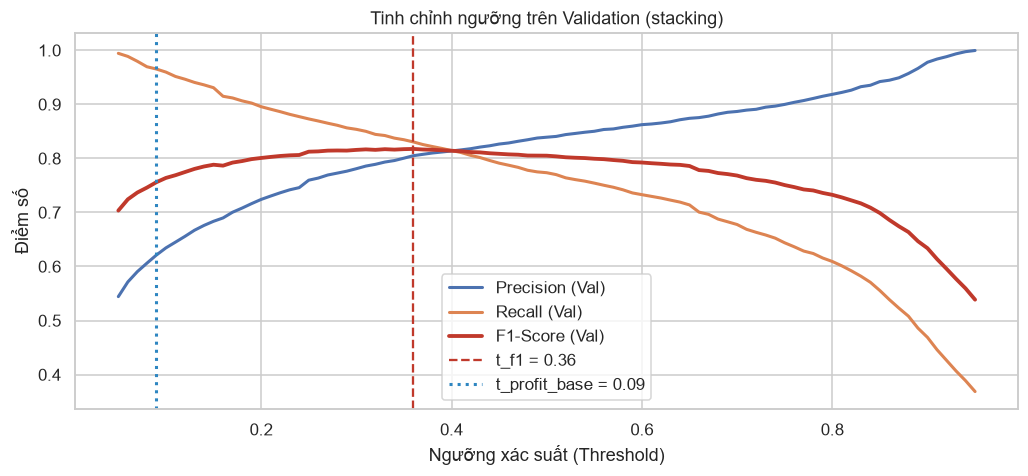

In [2]:
THRESHOLDS = np.round(np.arange(0.05, 0.951, 0.01), 2)

SCENARIOS = {
    'conservative': {
        'label': 'Thận trọng (Conservative)',
        'intervention_cost': 15.0,
        'intervention_success_rate': 0.20,
        'cancellation_loss_fraction': 0.70,
        'organic_resale_prob': 0.45,
    },
    'base': {
        'label': 'Cơ sở (Base)',
        'intervention_cost': 10.0,
        'intervention_success_rate': 0.35,
        'cancellation_loss_fraction': 0.85,
        'organic_resale_prob': 0.30,
    },
    'optimistic': {
        'label': 'Lạc quan (Optimistic)',
        'intervention_cost': 6.0,
        'intervention_success_rate': 0.50,
        'cancellation_loss_fraction': 1.00,
        'organic_resale_prob': 0.15,
    },
}

def simulate_net_value(y_true, y_prob, value_proxy, threshold, cfg):
    y_hat = (y_prob >= threshold).astype(int)
    net_recovery_factor = cfg['cancellation_loss_fraction'] * (1.0 - cfg['organic_resale_prob']) * cfg['intervention_success_rate']
    tp_mask = (y_true == 1) & (y_hat == 1)
    fp_mask = (y_true == 0) & (y_hat == 1)
    tp_gain = np.sum(value_proxy[tp_mask] * net_recovery_factor - cfg['intervention_cost'])
    fp_cost = np.sum(fp_mask) * (-cfg['intervention_cost'])
    return float(tp_gain + fp_cost), int(y_hat.sum()), float(net_recovery_factor)

# 1.1 Dự đoán trên Validation & tìm t_f1 riêng cho từng mô hình
val_probs = {name: mdl.predict_proba(X_val)[:, 1] for name, mdl in models.items()}
val_thresholds = {}
val_summary_rows = []

for name in ['lgbm', 'xgb', 'catboost', 'ensemble', 'best_model']:
    p = val_probs[name]
    f1s = [f1_score(y_val, (p >= t).astype(int)) for t in THRESHOLDS]
    best_idx = int(np.argmax(f1s))
    t_f1 = float(THRESHOLDS[best_idx])
    val_thresholds[name] = {'t_f1': t_f1}
    val_summary_rows.append({
        'model': name,
        'val_pr_auc': round(float(average_precision_score(y_val, p)), 4),
        'val_roc_auc': round(float(roc_auc_score(y_val, p)), 4),
        'val_brier': round(float(brier_score_loss(y_val, p)), 4),
        'val_t_f1': t_f1,
        'val_f1_at_t_f1': round(float(f1s[best_idx]), 4),
        'val_f1_at_050': round(float(f1_score(y_val, (p >= 0.5).astype(int))), 4),
    })

val_summary_df = pd.DataFrame(val_summary_rows)
print('--- Ngưỡng tối ưu F1 riêng từng mô hình trên Validation (~16%) ---')
display(val_summary_df)

# 1.2 Tối ưu ngưỡng lợi ích mô phỏng cho best_model trên Validation (3 kịch bản)
val_proxy = meta_val['estimated_booking_value_proxy'].to_numpy(dtype=float)
p_val_best = val_probs['best_model']
scenario_thresholds = {}

for sc_key, cfg in SCENARIOS.items():
    vals = [simulate_net_value(y_val.to_numpy(), p_val_best, val_proxy, t, cfg)[0] for t in THRESHOLDS]
    best_i = int(np.argmax(vals))
    scenario_thresholds[sc_key] = {
        't_profit': float(THRESHOLDS[best_i]),
        'val_net_value_eur': round(float(vals[best_i]), 2),
    }
    print(f'[{cfg["label"]:28s}] Ngưỡng tối ưu Validation = {THRESHOLDS[best_i]:.2f} | Giá trị ròng mô phỏng (Val) = {vals[best_i]:,.0f} EUR')

# Biểu đồ inline: Precision / Recall / F1 theo ngưỡng trên Validation (best_model)
precs = [precision_score(y_val, (p_val_best >= t).astype(int), zero_division=0) for t in THRESHOLDS]
recs = [recall_score(y_val, (p_val_best >= t).astype(int), zero_division=0) for t in THRESHOLDS]
f1s_best = [f1_score(y_val, (p_val_best >= t).astype(int), zero_division=0) for t in THRESHOLDS]

fig, ax = plt.subplots(figsize=(9.5, 4.5))
ax.plot(THRESHOLDS, precs, label='Precision (Val)', linewidth=2)
ax.plot(THRESHOLDS, recs, label='Recall (Val)', linewidth=2)
ax.plot(THRESHOLDS, f1s_best, label='F1-Score (Val)', linewidth=2.5, color='#C0392B')
ax.axvline(val_thresholds['best_model']['t_f1'], color='#C0392B', linestyle='--', label=f't_f1 = {val_thresholds["best_model"]["t_f1"]:.2f}')
ax.axvline(scenario_thresholds['base']['t_profit'], color='#2E86C1', linestyle=':', linewidth=2, label=f't_profit_base = {scenario_thresholds["base"]["t_profit"]:.2f}')
ax.set_title(f'Tinh chỉnh ngưỡng trên Validation ({BEST_MODEL_NAME})')
ax.set_xlabel('Ngưỡng xác suất (Threshold)')
ax.set_ylabel('Điểm số')
ax.legend()
plt.tight_layout()
plt.show()

## 2. Đánh giá cuối cùng trên tập Test chưa chạm tới (~20% Test)

Mọi ngưỡng đã được **đóng băng từ Validation**. Bây giờ ta đánh giá toàn bộ mô hình trên Test:
- **Bảng 2A — Thước đo độc lập ngưỡng**: `PR-AUC (Average Precision)`, `ROC-AUC`, `LogLoss`, `Brier Score`.
- **Bảng 2B — Thước đo phụ thuộc ngưỡng**: Mỗi mô hình sử dụng **chính ngưỡng `t_f1` riêng của nó từ Validation** (và mốc tham chiếu chung `0.50`).

--- Bảng 2A: Thước đo ĐỘC LẬP NGƯỠNG trên tập Test (~20%) ---

--- Bảng 2B: Thước đo PHỤ THUỘC NGƯỠNG trên tập Test (dùng t_f1 riêng từ Validation) ---


,model,test_pr_auc,test_roc_auc,test_logloss,test_brier
0,lgbm,0.9060,0.9341,0.3038,0.0993
1,xgb,0.9069,0.9344,0.3033,0.0990
2,catboost,0.9064,0.9349,0.3013,0.0988
3,ensemble,0.9087,0.9361,0.3205,0.1009
4,best_model,0.9087,0.9361,0.3205,0.1009


,model,own_val_t_f1,f1_at_own_t,precision_at_own_t,recall_at_own_t,bal_acc_at_own_t,f1_at_050
0,lgbm,0.47,0.8026,0.8117,0.7937,0.8425,0.8016
1,xgb,0.38,0.8030,0.7721,0.8366,0.8454,0.8006
2,catboost,0.38,0.8035,0.7698,0.8402,0.8459,0.7972
3,ensemble,0.36,0.8074,0.7856,0.8304,0.8483,0.8019
4,best_model,0.36,0.8074,0.7856,0.8304,0.8483,0.8019


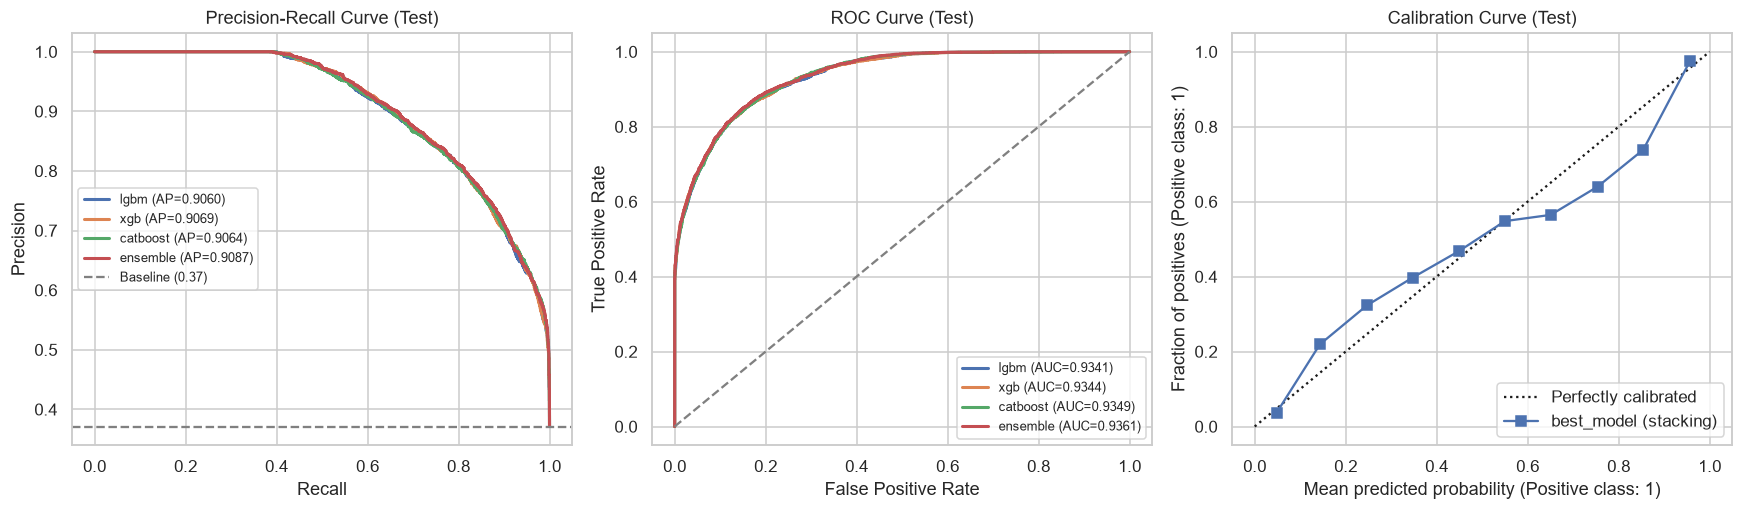

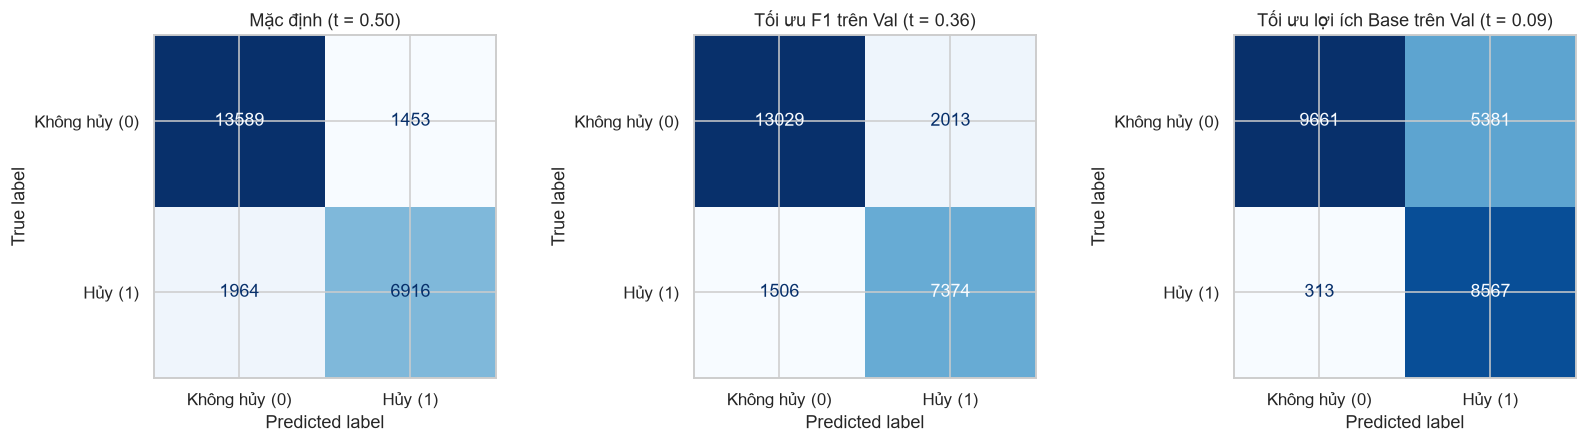

In [3]:
test_probs = {name: mdl.predict_proba(X_test)[:, 1] for name, mdl in models.items()}

indep_rows = []
dep_rows = []

for name in ['lgbm', 'xgb', 'catboost', 'ensemble', 'best_model']:
    p = test_probs[name]
    t_own = val_thresholds[name]['t_f1']
    y_hat_05 = (p >= 0.50).astype(int)
    y_hat_own = (p >= t_own).astype(int)

    indep_rows.append({
        'model': name,
        'test_pr_auc': round(float(average_precision_score(y_test, p)), 4),
        'test_roc_auc': round(float(roc_auc_score(y_test, p)), 4),
        'test_logloss': round(float(log_loss(y_test, p)), 4),
        'test_brier': round(float(brier_score_loss(y_test, p)), 4),
    })
    dep_rows.append({
        'model': name,
        'own_val_t_f1': t_own,
        'f1_at_own_t': round(float(f1_score(y_test, y_hat_own)), 4),
        'precision_at_own_t': round(float(precision_score(y_test, y_hat_own)), 4),
        'recall_at_own_t': round(float(recall_score(y_test, y_hat_own)), 4),
        'bal_acc_at_own_t': round(float(balanced_accuracy_score(y_test, y_hat_own)), 4),
        'f1_at_050': round(float(f1_score(y_test, y_hat_05)), 4),
    })

test_indep_df = pd.DataFrame(indep_rows)
test_dep_df = pd.DataFrame(dep_rows)
print('--- Bảng 2A: Thước đo ĐỘC LẬP NGƯỠNG trên tập Test (~20%) ---')
display(test_indep_df)
print('\n--- Bảng 2B: Thước đo PHỤ THUỘC NGƯỠNG trên tập Test (dùng t_f1 riêng từ Validation) ---')
display(test_dep_df)

# Biểu đồ inline: PR Curve, ROC Curve & Calibration Curve trên Test
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for name in ['lgbm', 'xgb', 'catboost', 'ensemble']:
    p = test_probs[name]
    prec, rec, _ = precision_recall_curve(y_test, p)
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(rec, prec, linewidth=2, label=f'{name} (AP={average_precision_score(y_test, p):.4f})')
    axes[1].plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={roc_auc_score(y_test, p):.4f})')

axes[0].axhline(y_test.mean(), linestyle='--', color='gray', label=f'Baseline ({y_test.mean():.2f})')
axes[0].set_title('Precision-Recall Curve (Test)')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].legend(fontsize=8.5)

axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title('ROC Curve (Test)')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(fontsize=8.5)

CalibrationDisplay.from_predictions(y_test, test_probs['best_model'], n_bins=10, name=f'best_model ({BEST_MODEL_NAME})', ax=axes[2])
axes[2].set_title('Calibration Curve (Test)')

plt.tight_layout()
plt.show()

# Ma trận nhầm lẫn trên Test (best_model) tại 0.50 vs t_f1 vs t_profit_base
p_test_best = test_probs['best_model']
t_f1_best = val_thresholds['best_model']['t_f1']
t_prof_base = scenario_thresholds['base']['t_profit']

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (title, thr) in zip(axes, [
    ('Mặc định (t = 0.50)', 0.50),
    (f'Tối ưu F1 trên Val (t = {t_f1_best:.2f})', t_f1_best),
    (f'Tối ưu lợi ích Base trên Val (t = {t_prof_base:.2f})', t_prof_base),
]):
    cm = confusion_matrix(y_test, (p_test_best >= thr).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=['Không hủy (0)', 'Hủy (1)']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 3. Đánh giá Mô phỏng Kịch bản Kinh doanh trên Test (Kèm kiểm tra độ nhạy Ngoại lai ADR)

Áp dụng đúng các ngưỡng đã đóng băng trên Validation vào tập Test (so với mốc `No Intervention = 0 EUR`), đồng thời kiểm tra xem bản ghi `is_extreme_adr == 1` (`adr > 1000`, nếu rơi vào Test) có làm méo kết quả mô phỏng hay không.  
*Lưu ý: Đây là mô phỏng dựa trên `estimated_booking_value_proxy` và bộ giả định kịch bản, **không phải ROI thực tế đã kiểm toán**.*

Số bản ghi is_extreme_adr==1 trong Test: 0


,Kịch bản,Chính sách ngưỡng,Ngưỡng,Số đơn gắn cờ,Tỷ lệ gắn cờ (%),Hệ số thu hồi ròng,Giá trị ròng mô phỏng (EUR),Không tính ADR>1000 (EUR)
0,Thận trọng (Conservative),Default (0.50),0.50,8369,35.0,0.0770,75451.0,75451.0
1,Thận trọng (Conservative),Val F1-Optimal (0.36),0.36,9387,39.2,0.0770,75888.0,75888.0
2,Thận trọng (Conservative),Val Profit-Optimal (0.36),0.36,9387,39.2,0.0770,75888.0,75888.0
3,Cơ sở (Base),Default (0.50),0.50,8369,35.0,0.2082,459886.0,459886.0
4,Cơ sở (Base),Val F1-Optimal (0.36),0.36,9387,39.2,0.2082,492187.0,492187.0
5,Cơ sở (Base),Val Profit-Optimal (0.09),0.09,13948,58.3,0.2082,540751.0,540751.0
6,Lạc quan (Optimistic),Default (0.50),0.50,8369,35.0,0.4250,1059125.0,1059125.0
7,Lạc quan (Optimistic),Val F1-Optimal (0.36),0.36,9387,39.2,0.4250,1139713.0,1139713.0
8,Lạc quan (Optimistic),Val Profit-Optimal (0.05),0.05,16377,68.5,0.4250,1320513.0,1320513.0


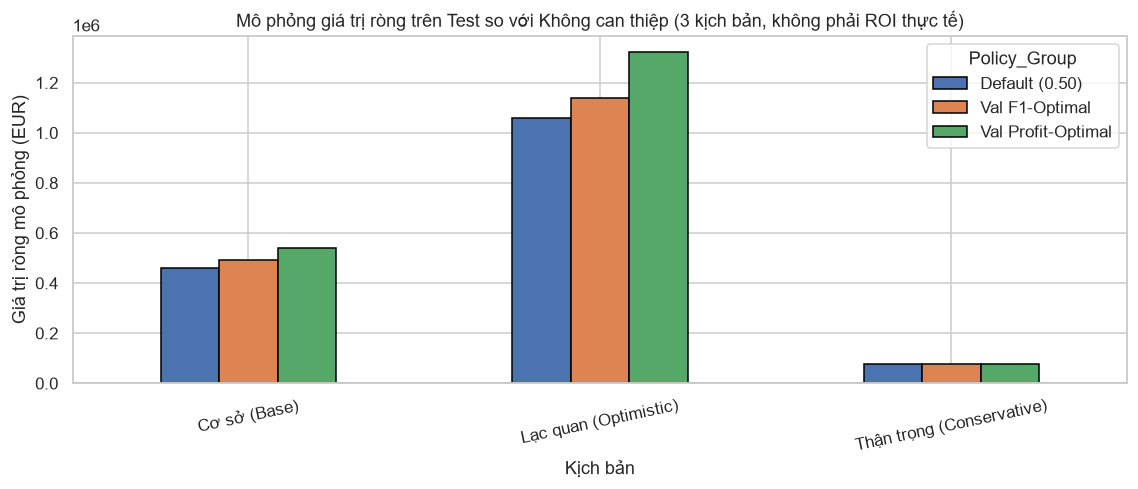

In [4]:
test_proxy = meta_test['estimated_booking_value_proxy'].to_numpy(dtype=float)
y_test_np = y_test.to_numpy()
no_ext_mask = (meta_test['is_extreme_adr'].to_numpy() == 0)

biz_rows = []
for sc_key, cfg in SCENARIOS.items():
    t_prof = scenario_thresholds[sc_key]['t_profit']
    for policy_name, thr in [
        ('Default (0.50)', 0.50),
        (f'Val F1-Optimal ({t_f1_best:.2f})', t_f1_best),
        (f'Val Profit-Optimal ({t_prof:.2f})', t_prof),
    ]:
        net_all, n_flagged, rec_factor = simulate_net_value(y_test_np, p_test_best, test_proxy, thr, cfg)
        net_no_ext, _, _ = simulate_net_value(y_test_np[no_ext_mask], p_test_best[no_ext_mask], test_proxy[no_ext_mask], thr, cfg)
        biz_rows.append({
            'Kịch bản': cfg['label'],
            'Chính sách ngưỡng': policy_name,
            'Ngưỡng': thr,
            'Số đơn gắn cờ': n_flagged,
            'Tỷ lệ gắn cờ (%)': round(n_flagged / len(y_test_np) * 100, 1),
            'Hệ số thu hồi ròng': round(rec_factor, 4),
            'Giá trị ròng mô phỏng (EUR)': round(net_all, 0),
            'Không tính ADR>1000 (EUR)': round(net_no_ext, 0),
        })

biz_df = pd.DataFrame(biz_rows)
print(f'Số bản ghi is_extreme_adr==1 trong Test: {int((~no_ext_mask).sum())}')
display(biz_df)

# Biểu đồ inline so sánh 3 kịch bản
fig, ax = plt.subplots(figsize=(10.5, 4.6))
piv = biz_df.pivot(index='Kịch bản', columns='Chính sách ngưỡng', values='Giá trị ròng mô phỏng (EUR)')
# Gom gọn 3 nhóm chính sách bằng vị trí cột
plot_biz = biz_df.copy()
plot_biz['Policy_Group'] = plot_biz['Chính sách ngưỡng'].apply(
    lambda s: 'Default (0.50)' if 'Default' in s else ('Val F1-Optimal' if 'F1' in s else 'Val Profit-Optimal')
)
piv2 = plot_biz.pivot(index='Kịch bản', columns='Policy_Group', values='Giá trị ròng mô phỏng (EUR)')
piv2[['Default (0.50)', 'Val F1-Optimal', 'Val Profit-Optimal']].plot(kind='bar', ax=ax, edgecolor='black')
ax.axhline(0, color='black', linewidth=1)
ax.set_title('Mô phỏng giá trị ròng trên Test so với Không can thiệp (3 kịch bản, không phải ROI thực tế)')
ax.set_ylabel('Giá trị ròng mô phỏng (EUR)')
ax.tick_params(axis='x', rotation=12)
plt.tight_layout()
plt.show()

## 4. Thí nghiệm nâng cao: Kiểm định theo thời gian (Temporal Validation: 2015–2016 → 2017)

Sử dụng cột `arrival_date_year` được lưu riêng trong `METADATA_COLS` (vẫn loại hoàn toàn khỏi `MODEL_FEATURES`), ta huấn luyện lại kiến trúc mô hình thắng cuộc trên các đơn năm **2015–2016** và kiểm định trên toàn bộ đơn năm **2017** để đo lường mức độ dịch chuyển phân phối theo thời gian (temporal drift).

In [5]:
temp_train_mask = meta_all['arrival_date_year'].isin([2015, 2016]).to_numpy()
temp_test_mask = (meta_all['arrival_date_year'] == 2017).to_numpy()

X_t_tr, y_t_tr = X_all.loc[temp_train_mask].reset_index(drop=True), y_all.loc[temp_train_mask].reset_index(drop=True)
X_t_te, y_t_te = X_all.loc[temp_test_mask].reset_index(drop=True), y_all.loc[temp_test_mask].reset_index(drop=True)

# Clone mô hình cơ sở tương ứng (dùng lgbm nếu best_model là stacking để tránh cố định index internal_cv cũ)
temp_model_name = BEST_MODEL_NAME if BEST_MODEL_NAME != 'stacking' else 'voting'
if BEST_MODEL_NAME == 'stacking':
    # Tạo VotingClassifier từ 3 mô hình đã tinh chỉnh cho Temporal check
    from sklearn.ensemble import VotingClassifier
    temp_model = VotingClassifier(
        estimators=[('lgbm', clone(models['lgbm'])), ('xgb', clone(models['xgb'])), ('catboost', clone(models['catboost']))],
        voting='soft', n_jobs=1
    )
else:
    temp_model = clone(models['best_model'])

temp_model.fit(X_t_tr, y_t_tr)
p_t_te = temp_model.predict_proba(X_t_te)[:, 1]
y_t_hat = (p_t_te >= 0.50).astype(int)

temporal_metrics = {
    'train_years': [2015, 2016],
    'test_year': 2017,
    'n_train': int(len(X_t_tr)),
    'n_test': int(len(X_t_te)),
    'train_cancel_rate': round(float(y_t_tr.mean()), 4),
    'test_cancel_rate': round(float(y_t_te.mean()), 4),
    'model_used': temp_model_name,
    'pr_auc': round(float(average_precision_score(y_t_te, p_t_te)), 4),
    'roc_auc': round(float(roc_auc_score(y_t_te, p_t_te)), 4),
    'logloss': round(float(log_loss(y_t_te, p_t_te)), 4),
    'brier': round(float(brier_score_loss(y_t_te, p_t_te)), 4),
    'f1_at_050': round(float(f1_score(y_t_te, y_t_hat)), 4),
}

comp_temp = pd.DataFrame([
    {'Kịch bản đánh giá': 'Group-Aware Holdout Test (~20%)',
     'PR-AUC': float(test_indep_df.set_index('model').loc['best_model', 'test_pr_auc']),
     'ROC-AUC': float(test_indep_df.set_index('model').loc['best_model', 'test_roc_auc']),
     'Brier': float(test_indep_df.set_index('model').loc['best_model', 'test_brier']),
     'F1@0.50': float(test_dep_df.set_index('model').loc['best_model', 'f1_at_050'])},
    {'Kịch bản đánh giá': 'Temporal Validation (2015-2016 -> 2017)',
     'PR-AUC': temporal_metrics['pr_auc'],
     'ROC-AUC': temporal_metrics['roc_auc'],
     'Brier': temporal_metrics['brier'],
     'F1@0.50': temporal_metrics['f1_at_050']},
])
display(comp_temp)

,Kịch bản đánh giá,PR-AUC,ROC-AUC,Brier,F1@0.50
0,Group-Aware Holdout Test (~20%),0.9087,0.9361,0.1009,0.8019
1,Temporal Validation (2015-2016 -> 2017),0.8407,0.8846,0.1444,0.6936


## 5. Giải thích mô hình & Phân tích lỗi (Explainability & Error Analysis)

Sử dụng hoàn toàn các công cụ trong `scikit-learn` (không cần cài thêm SHAP):
- `permutation_importance` (theo `average_precision`) để xếp hạng Top 15 đặc trưng ảnh hưởng mạnh nhất trên tập Test.
- `PartialDependenceDisplay` cho 4 đặc trưng số chủ lực (`lead_time`, `total_of_special_requests`, `previous_cancellations`, `total_nights`).
- Phân tích tỷ lệ lỗi (False Positive Rate & False Negative Rate) theo `hotel`, `market_segment`, `deposit_type` và `arrival_date_year`.


--- Phân tích lỗi theo hotel (t = 0.36) ---

--- Phân tích lỗi theo deposit_type (t = 0.36) ---

--- Phân tích lỗi theo arrival_date_year (t = 0.36) ---

--- Phân tích lỗi theo market_segment (t = 0.36) ---


,feature,importance_mean,importance_std
0,deposit_type,0.112499,0.004513
1,agent,0.058927,0.000940
2,lead_time,0.049421,0.001932
3,market_segment,0.036766,0.001482
4,is_portugal,0.036046,0.001351
5,customer_type,0.028113,0.002747
6,prev_cancel_ratio,0.027600,0.001762
7,total_of_special_requests,0.022558,0.001375
8,country,0.014836,0.000992
9,required_car_parking_spaces,0.014119,0.000824


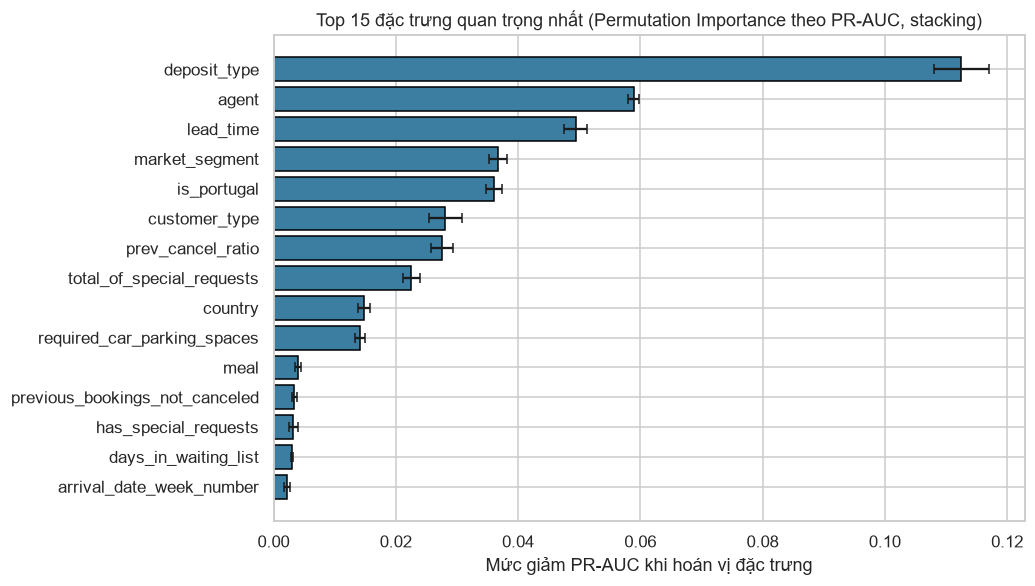

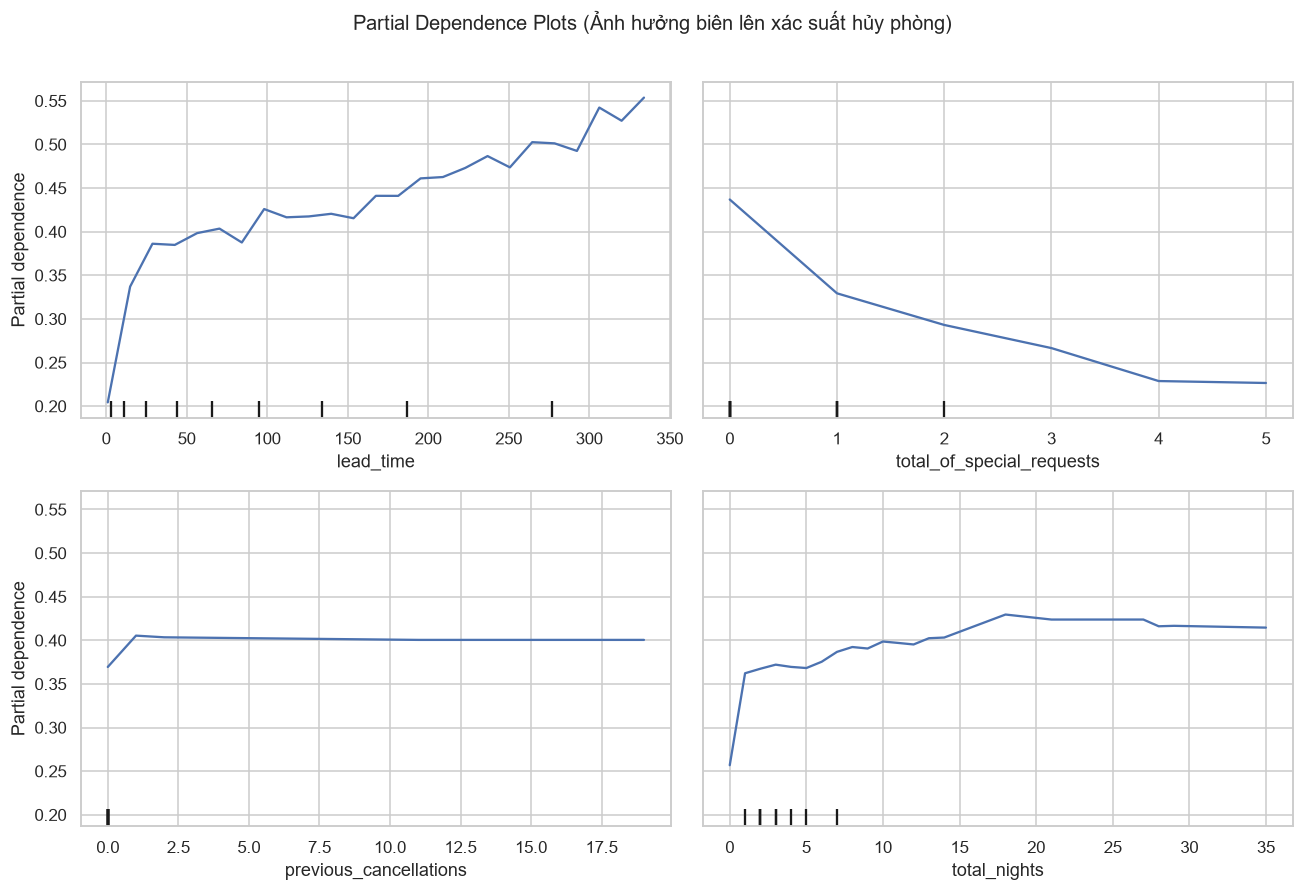

,n,cancel_rate,error_rate,fp_rate,fn_rate
hotel,,,,,
City Hotel,15920,42.0,15.5,8.5,6.9
Resort Hotel,8002,27.5,13.2,8.2,5.0


,n,cancel_rate,error_rate,fp_rate,fn_rate
deposit_type,,,,,
No Deposit,20830,28.0,16.9,9.6,7.2
Non Refund,3071,99.5,0.3,0.3,0.0
Refundable,21,4.8,0.0,0.0,0.0


,n,cancel_rate,error_rate,fp_rate,fn_rate
arrival_date_year,,,,,
2016,11189,36.4,13.7,8.2,5.5
2017,8281,38.4,17.9,9.5,8.5
2015,4452,36.5,11.4,7.1,4.3


,n,cancel_rate,error_rate,fp_rate,fn_rate
market_segment,,,,,
Online TA,11119,36.3,21.1,13.6,7.6
Offline TA/TO,4985,34.7,8.1,5.4,2.7
Groups,4119,60.7,6.3,2.8,3.5
Direct,2485,17.1,14.2,2.7,11.5
Corporate,990,15.4,11.9,4.0,7.9
Complementary,177,11.3,11.3,4.5,6.8
Aviation,47,25.5,25.5,2.1,23.4


In [6]:
# 5.1 Permutation Importance trên tập Test (lấy mẫu 8,000 dòng cố định SEED để chạy nhanh & ổn định)
rng = np.random.RandomState(SEED)
sub_idx = rng.choice(len(X_test), size=min(8000, len(X_test)), replace=False)
X_test_sub = X_test.iloc[sub_idx].reset_index(drop=True)
y_test_sub = y_test.iloc[sub_idx].reset_index(drop=True)

perm = permutation_importance(
    models['best_model'], X_test_sub, y_test_sub,
    scoring='average_precision', n_repeats=5, random_state=SEED, n_jobs=1
)
imp_df = pd.DataFrame({
    'feature': MODEL_FEATURES,
    'importance_mean': perm.importances_mean,
    'importance_std': perm.importances_std,
}).sort_values('importance_mean', ascending=False).reset_index(drop=True)

display(imp_df.head(15))

fig, ax = plt.subplots(figsize=(9.5, 5.5))
top15 = imp_df.head(15).sort_values('importance_mean', ascending=True)
ax.barh(top15['feature'], top15['importance_mean'], xerr=top15['importance_std'], color='#3B7EA1', edgecolor='black', capsize=3)
ax.set_title(f'Top 15 đặc trưng quan trọng nhất (Permutation Importance theo PR-AUC, {BEST_MODEL_NAME})')
ax.set_xlabel('Mức giảm PR-AUC khi hoán vị đặc trưng')
plt.tight_layout()
plt.show()

# 5.2 Partial Dependence Plots cho 4 biến số chủ chốt (ép kiểu float theo yêu cầu sklearn >= 1.9)
pdp_features = ['lead_time', 'total_of_special_requests', 'previous_cancellations', 'total_nights']
X_pdp = X_test_sub.iloc[:2000].copy()
for c in pdp_features:
    X_pdp[c] = X_pdp[c].astype(float)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
PartialDependenceDisplay.from_estimator(
    models['best_model'], X_pdp, features=pdp_features,
    ax=axes, grid_resolution=25
)
fig.suptitle('Partial Dependence Plots (Ảnh hưởng biên lên xác suất hủy phòng)', y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

# 5.3 Phân tích lỗi theo hotel, market_segment, deposit_type, arrival_date_year
err_df = X_test[['hotel', 'market_segment', 'deposit_type']].copy()
err_df['arrival_date_year'] = meta_test['arrival_date_year'].values
err_df['y_true'] = y_test.values
err_df['y_pred'] = (p_test_best >= t_f1_best).astype(int)
err_df['is_fp'] = ((err_df['y_true'] == 0) & (err_df['y_pred'] == 1)).astype(int)
err_df['is_fn'] = ((err_df['y_true'] == 1) & (err_df['y_pred'] == 0)).astype(int)
err_df['is_err'] = (err_df['y_true'] != err_df['y_pred']).astype(int)

for grp_col in ['hotel', 'deposit_type', 'arrival_date_year', 'market_segment']:
    print(f'\n--- Phân tích lỗi theo {grp_col} (t = {t_f1_best:.2f}) ---')
    summary = err_df.groupby(grp_col).agg(
        n=('y_true', 'count'),
        cancel_rate=('y_true', 'mean'),
        error_rate=('is_err', 'mean'),
        fp_rate=('is_fp', 'mean'),
        fn_rate=('is_fn', 'mean'),
    ).sort_values('n', ascending=False)
    display((summary.assign(
        cancel_rate=(summary['cancel_rate']*100).round(1),
        error_rate=(summary['error_rate']*100).round(1),
        fp_rate=(summary['fp_rate']*100).round(1),
        fn_rate=(summary['fn_rate']*100).round(1),
    )))

## 6. Lưu Siêu dữ liệu cuối (`artifacts/model_metadata.json`) & Demo Suy luận tái sử dụng

Lưu toàn bộ thông tin truy xuất (mô hình được chọn, ngưỡng tối ưu riêng từng mô hình & kịch bản, danh sách `MODEL_FEATURES`, cấu hình chia tập, kết quả Validation / Test / Temporal, phiên bản thư viện) ra `artifacts/model_metadata.json` (bên ngoài thư mục `model/`), và chạy thử hàm `predict_cancellation_risk()` trên 3 mẫu đặt phòng mới tại thời điểm xác nhận.

In [7]:
# 6.1 Lưu artifacts/model_metadata.json
model_metadata = {
    'selected_model_name': BEST_MODEL_NAME,
    'model_artifact_path': 'model/best_model.joblib',
    'prediction_cutoff': 'Booking Confirmation (strict — excludes reservation_status, assigned_room_type, booking_changes, adr, and ADR-derived features)',
    'random_seed': SEED,
    'frozen_thresholds_from_validation': {
        'per_model_t_f1': {k: v['t_f1'] for k, v in val_thresholds.items()},
        'best_model_t_f1': val_thresholds['best_model']['t_f1'],
        'best_model_business_scenarios': scenario_thresholds,
    },
    'business_simulation_assumptions': SCENARIOS,
    'model_features': MODEL_FEATURES,
    'metadata_cols': METADATA_COLS,
    'split_configuration': split_meta['splits'],
    'validation_results': val_summary_df.to_dict(orient='records'),
    'test_results_threshold_independent': test_indep_df.to_dict(orient='records'),
    'test_results_threshold_dependent': test_dep_df.to_dict(orient='records'),
    'temporal_validation_2015_2016_to_2017': temporal_metrics,
    'package_versions': split_meta['package_versions'],
}
meta_path = ARTIFACT_DIR / 'model_metadata.json'
meta_path.write_text(json.dumps(model_metadata, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'Đã lưu thành công: {meta_path.resolve()}')

# 6.2 Demo hàm suy luận tái sử dụng (tải trực tiếp từ model/best_model.joblib & artifacts/model_metadata.json)
def predict_cancellation_risk(booking_df: pd.DataFrame,
                              model_path: Path = Path('model/best_model.joblib'),
                              metadata_path: Path = Path('artifacts/model_metadata.json')) -> pd.DataFrame:
    model = joblib.load(model_path)
    meta = json.loads(metadata_path.read_text(encoding='utf-8'))
    feats = meta['model_features']
    thr = float(meta['frozen_thresholds_from_validation']['best_model_t_f1'])

    X_in = booking_df[feats].copy()
    probs = model.predict_proba(X_in)[:, 1]
    preds = (probs >= thr).astype(int)

    tiers = []
    actions = []
    for p in probs:
        if p < 0.30:
            tiers.append('Thấp')
            actions.append('Quy trình chuẩn — không cần can thiệp')
        elif p < thr:
            tiers.append('Trung bình')
            actions.append('Gửi email xác nhận & nhắc lịch trước 7 ngày')
        else:
            tiers.append('Cao')
            actions.append('Ưu tiên liên hệ xác nhận / áp dụng chính sách giữ phòng linh hoạt')

    return pd.DataFrame({
        'cancel_probability': np.round(probs, 4),
        'predicted_cancel': preds,
        'threshold_used': thr,
        'risk_tier': tiers,
        'recommended_action': actions,
    })

# Lấy 3 hồ sơ đại diện (rủi ro thấp, trung bình, cao) từ X_test để minh họa suy luận
sample_indices = [
    int(np.argmin(p_test_best)),
    int(np.argmin(np.abs(p_test_best - 0.38))),
    int(np.argmax(p_test_best)),
]
sample_bookings = X_test.iloc[sample_indices].reset_index(drop=True)
demo_out = predict_cancellation_risk(sample_bookings)
demo_view = pd.concat([
    sample_bookings[['hotel', 'lead_time', 'deposit_type', 'market_segment', 'total_of_special_requests', 'previous_cancellations']],
    demo_out
], axis=1)
print('\n--- Demo Suy luận trên 3 đơn đặt phòng mẫu (tại thời điểm xác nhận) ---')
display(demo_view)

Đã lưu thành công: E:\repos\ML\MachineLearning\artifacts\model_metadata.json

--- Demo Suy luận trên 3 đơn đặt phòng mẫu (tại thời điểm xác nhận) ---


,hotel,lead_time,deposit_type,market_segment,total_of_special_requests,previous_cancellations,cancel_probability,predicted_cancel,threshold_used,risk_tier,recommended_action
0,Resort Hotel,383,No Deposit,Groups,0,0,0.0371,0,0.36,Thấp,Quy trình chuẩn — không cần can thiệp
1,City Hotel,16,No Deposit,Online TA,1,0,0.3800,1,0.36,Cao,Ưu tiên liên hệ xác nhận / áp dụng chính sách giữ phòng linh hoạt
2,City Hotel,344,Non Refund,Groups,0,1,0.9667,1,0.36,Cao,Ưu tiên liên hệ xác nhận / áp dụng chính sách giữ phòng linh hoạt
